<a href="https://colab.research.google.com/github/abirbekkar/Machine-learning-course/blob/TP-Solution/Data_Preprocessing_Teaching_Notebook_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing

## Contents

1. Understanding the data
2. Removing unnecessary data
3. Missing values
4. Outliers
5. Standardization and normalization
6. Encoding categorical variables
7. Revision

## Dataset

[Student Academic Performance Dataset](https://github.com/abirbekkar/Machine-learning-course/blob/TP-Solution/student_academic_performance_dataset%281%29.csv)

The dataset was created for preprocessing exercises using student academic performance data. It includes missing values, duplicate rows, and extreme values to practice data cleaning and preprocessing techniques. The examples use `exam_score` to detect and cap outliers in students' exam scores.

Enable Internet access and run the cells in order.

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OrdinalEncoder
from IPython.display import display as data

### Load the dataset

In [79]:
source_url = (
    "https://raw.githubusercontent.com/"
    "abirbekkar/Machine-learning-course/"
    "TP-Solution/student_academic_performance_dataset%281%29.csv"
)

data = pd.read_csv(source_url)
raw_data = data.copy()

print("Shape:", data.shape)
display(data.head())

Shape: (105, 12)


,student_id,age,gender,specialty,study_year,study_hours_per_week,absences,average_grade,exam_score,scholarship,housing_type,parent_education
0,STU001,19.0,Female,Artificial Intelligence,Master 2,13.4,7.0,9.27,14.33,Yes,Family,Primary
1,STU002,27.0,Female,Chemistry,Master 1,3.5,5.0,10.24,8.68,No,University,NaN
2,STU003,25.0,Male,NaN,2nd Year,5.2,5.0,13.69,18.05,No,Rental,NaN
3,STU004,23.0,Male,Chemistry,Master 2,26.8,NaN,14.17,11.25,No,Family,NaN
4,STU005,23.0,Male,Mathematics,NaN,95.0,7.0,NaN,7.21,No,Family,NaN


## 1. Understanding the data

In [80]:
data.shape

(105, 12)

In [81]:
data.columns

Index(['student_id', 'age', 'gender', 'specialty', 'study_year',
       'study_hours_per_week', 'absences', 'average_grade', 'exam_score',
       'scholarship', 'housing_type', 'parent_education'],
      dtype='object')

In [82]:
data.head()

,student_id,age,gender,specialty,study_year,study_hours_per_week,absences,average_grade,exam_score,scholarship,housing_type,parent_education
0,STU001,19.0,Female,Artificial Intelligence,Master 2,13.4,7.0,9.27,14.33,Yes,Family,Primary
1,STU002,27.0,Female,Chemistry,Master 1,3.5,5.0,10.24,8.68,No,University,NaN
2,STU003,25.0,Male,NaN,2nd Year,5.2,5.0,13.69,18.05,No,Rental,NaN
3,STU004,23.0,Male,Chemistry,Master 2,26.8,NaN,14.17,11.25,No,Family,NaN
4,STU005,23.0,Male,Mathematics,NaN,95.0,7.0,NaN,7.21,No,Family,NaN


In [83]:
data.tail()

,student_id,age,gender,specialty,study_year,study_hours_per_week,absences,average_grade,exam_score,scholarship,housing_type,parent_education
100,STU003,25.0,Male,NaN,2nd Year,5.2,5.0,13.69,18.05,No,Rental,NaN
101,STU011,24.0,Male,Physics,1st Year,16.0,3.0,6.86,15.17,Yes,Rental,NaN
102,STU026,25.0,Female,Artificial Intelligence,1st Year,14.9,2.0,13.43,11.15,No,Rental,NaN
103,STU041,19.0,Female,Physics,Master 2,NaN,12.0,4.00,14.53,No,Rental,NaN
104,STU056,18.0,Male,Chemistry,3rd Year,15.8,7.0,12.39,NaN,No,Family,NaN


In [84]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            105 non-null    object 
 1   age                   101 non-null    float64
 2   gender                99 non-null     object 
 3   specialty             96 non-null     object 
 4   study_year            100 non-null    object 
 5   study_hours_per_week  92 non-null     float64
 6   absences              96 non-null     float64
 7   average_grade         95 non-null     float64
 8   exam_score            94 non-null     float64
 9   scholarship           98 non-null     object 
 10  housing_type          97 non-null     object 
 11  parent_education      18 non-null     object 
dtypes: float64(5), object(7)
memory usage: 10.0+ KB


In [85]:
data.describe()

,age,study_hours_per_week,absences,average_grade,exam_score
count,101.000000,92.000000,96.000000,95.000000,94.000000
mean,23.673267,15.615217,4.791667,12.927895,13.685532
std,3.334993,10.370467,2.348198,4.107019,5.633784
min,18.000000,1.000000,1.000000,4.000000,5.370000
25%,21.000000,11.125000,3.000000,11.155000,11.150000
50%,24.000000,15.250000,5.000000,13.130000,13.370000
75%,27.000000,18.700000,7.000000,14.610000,15.170000
max,29.000000,95.000000,12.000000,39.500000,58.000000


In [86]:
data.describe(include="object")

,student_id,gender,specialty,study_year,scholarship,housing_type,parent_education
count,105,99,96,100,98,97,18
unique,100,2,5,5,2,3,4
top,STU003,Female,Artificial Intelligence,1st Year,No,Rental,Primary
freq,2,57,24,24,59,36,8


### Unique values in categorical columns

In [87]:
categorical_columns = data.select_dtypes(include="object").columns

for column in categorical_columns:
    print(column, ":", data[column].nunique(), "unique values")

student_id : 100 unique values
gender : 2 unique values
specialty : 5 unique values
study_year : 5 unique values
scholarship : 2 unique values
housing_type : 3 unique values
parent_education : 4 unique values


## 2. Removing unnecessary data

### Duplicate rows

Find exact duplicate rows, then remove them.

In [88]:
data.duplicated().sum()

np.int64(5)

In [89]:
rows_before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", rows_before - len(data))
data.shape

Duplicate rows removed: 5


(100, 12)

### Missing values

In [90]:
missing_values = data.isnull().sum()

missing_table = pd.DataFrame({
    "Missing values": missing_values,
    "Percentage": missing_values / len(data) * 100
})

missing_table.sort_values("Percentage", ascending=False).round(2)

,Missing values,Percentage
parent_education,82,82.0
study_hours_per_week,12,12.0
average_grade,10,10.0
exam_score,10,10.0
absences,9,9.0
housing_type,8,8.0
specialty,8,8.0
scholarship,7,7.0
gender,6,6.0
study_year,5,5.0


Remove columns with **70% or more** missing values.

In [91]:
missing_threshold = 70
columns_to_remove = missing_table[
    missing_table["Percentage"] >= missing_threshold
].index.tolist()

columns_to_remove

['parent_education']

In [92]:
data = data.drop(columns=columns_to_remove)
print("Columns removed:", columns_to_remove)
data.shape

Columns removed: ['parent_education']


(100, 11)

## Rows with missing **values**

Compare removing every incomplete row with removing only rows that lack `exam_score`. Store the results in separate copies so that `data` still contains missing values for the imputation examples.

For a student exam-score prediction task, remove rows with a missing target rather than imputing the target value.

In [93]:
complete_rows = data.dropna()
score_rows = data.dropna(subset=["exam_score"])

row_removal_comparison = pd.DataFrame({
    "Rows kept": [len(data), len(complete_rows), len(score_rows)],
    "Rows removed": [0, len(data) - len(complete_rows), len(data) - len(score_rows)]
}, index=[
    "Before row removal",
    "Remove every incomplete row",
    "Remove rows missing exam_score"
])
row_removal_comparison

,Rows kept,Rows removed
Before row removal,100,0
Remove every incomplete row,47,53
Remove rows missing exam_score,90,10


## 3. Handling missing values

In [94]:
data.isnull().sum()

,0
student_id,0
age,4
gender,6
specialty,8
study_year,5
study_hours_per_week,12
absences,9
average_grade,10
exam_score,10
scholarship,7


### Numerical variables

Mean:

$$
\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
$$

The median is less sensitive to extreme values.

In [95]:
numeric_columns = data.select_dtypes(include=np.number).columns
numeric_columns

Index(['age', 'study_hours_per_week', 'absences', 'average_grade',
       'exam_score'],
      dtype='object')

#### Mean imputation

Use a copy of the data to compare mean and median imputation.

In [96]:
mean_example = data.copy()

for column in mean_example.select_dtypes(include=np.number).columns:
    mean_example[column] = mean_example[column].fillna(
        mean_example[column].mean()
    )

imputation_comparison = pd.DataFrame({
    "Missing before": data[numeric_columns].isnull().sum(),
    "Mean": data[numeric_columns].mean(),
    "Median": data[numeric_columns].median(),
    "Missing after imputation": mean_example[numeric_columns].isnull().sum(),
})
imputation_comparison

,Missing before,Mean,Median,Missing after imputation
age,4,23.750000,24.00,0
study_hours_per_week,12,15.735227,15.25,0
absences,9,4.736264,5.00,0
average_grade,10,13.086444,13.15,0
exam_score,10,13.639333,13.29,0


#### Median imputation

In [97]:
numerical_missing_before = data[numeric_columns].isnull().sum()

for column in numeric_columns:
    data[column] = data[column].fillna(data[column].median())

pd.DataFrame({
    "Missing before": numerical_missing_before,
    "Missing after": data[numeric_columns].isnull().sum()
})

,Missing before,Missing after
age,4,0
study_hours_per_week,12,0
absences,9,0
average_grade,10,0
exam_score,10,0


### Categorical variables

Replace missing values with the mode, the most frequent category.

In [98]:
categorical_columns = data.select_dtypes(include="object").columns
categorical_missing_before = data[categorical_columns].isnull().sum()

for column in categorical_columns:
    if data[column].isnull().any():
        data[column] = data[column].fillna(data[column].mode()[0])

pd.DataFrame({
    "Missing before": categorical_missing_before,
    "Missing after": data[categorical_columns].isnull().sum()
})

,Missing before,Missing after
student_id,0,0
gender,6,0
specialty,8,0
study_year,5,0
scholarship,7,0
housing_type,8,0


## 4. Outlier detection and treatment

### Interquartile range

$$
\mathrm{IQR} = Q_3 - Q_1
$$

Flag values outside these limits:

$$
L = Q_1 - 1.5\,\mathrm{IQR}, \qquad U = Q_3 + 1.5\,\mathrm{IQR}
$$

Use `exam_score` because `Exam Score` contains amounts in different currencies.

In [99]:
outlier_columns = ["exam_score"]

Q1 = data[outlier_columns].quantile(0.25)
Q3 = data[outlier_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower bound": lower_bound,
    "Upper bound": upper_bound,
})

,Q1,Q3,IQR,Lower bound,Upper bound
exam_score,11.25,14.9475,3.6975,5.70375,20.49375


In [100]:
outlier_count = {}

for column in outlier_columns:
    condition = (
        (data[column] < lower_bound[column]) |
        (data[column] > upper_bound[column])
    )
    outlier_count[column] = condition.sum()

pd.Series(outlier_count, name="Outliers")

,Outliers
exam_score,3


### Box plot

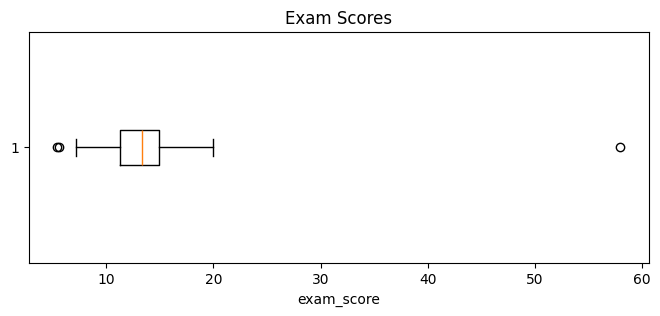

In [101]:
plt.figure(figsize=(8, 3))
plt.boxplot(data["exam_score"], vert=False)
plt.xlabel("exam_score")
plt.title("Exam Scores")
plt.show()

Cap `exam_score` at the IQR limits. Review flagged values before applying
capping to a real dataset, since some extreme scores may be valid.

In [102]:
score_q1 = data["exam_score"].quantile(0.25)
score_q3 = data["exam_score"].quantile(0.75)
score_iqr = score_q3 - score_q1

score_lower = score_q1 - 1.5 *  score_iqr
score_upper =  score_q3 + 1.5 *  score_iqr

data_capped = data.copy()
data_capped["exam_score"] = data_capped["exam_score"].clip(
    lower= score_lower,
    upper= score_upper
)

outside_before = (
    (data["exam_score"] <  score_lower) |
    (data["exam_score"] >  score_upper)
).sum()
outside_after = (
    (data_capped["exam_score"] <  score_lower) |
    (data_capped["exam_score"] >  score_upper)
).sum()
print("Outliers before capping:", outside_before)
print("Outliers after capping:", outside_after)
data_capped["exam_score"].describe()

Outliers before capping: 3
Outliers after capping: 0


,exam_score
count,100.000000
mean,13.233513
std,3.146763
min,5.703750
25%,11.250000
50%,13.290000
75%,14.947500
max,20.493750


## 5. Standardization and normalization

### Standardization

$$
z = \frac{x - \mu}{\sigma}
$$

For prediction tasks, fit preprocessing on the training data and use the same
parameters for the test data. Exclude `exam_score` and `Exam Score` from the
input features if `exam_score` is the prediction target.

In [103]:
numeric_columns = data_capped.select_dtypes(include=np.number).columns

standard_scaler = StandardScaler()

standardized_data = data_capped.copy()
standardized_data[numeric_columns] = standard_scaler.fit_transform(
    data_capped[numeric_columns]
)

standardized_data[numeric_columns].head()

,age,study_hours_per_week,absences,average_grade,exam_score
0,-1.466011,-0.231448,1.048700,-0.998532,0.350205
1,0.997873,-1.237741,0.112361,-0.745164,-1.454336
2,0.381902,-1.064943,0.112361,0.155991,1.538327
3,-0.234069,1.130606,0.112361,0.281369,-0.633510
4,-0.234069,8.062852,1.048700,0.014941,-1.923837


### Min-max normalization

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

In [104]:
minmax_scaler = MinMaxScaler()

normalized_data = data_capped.copy()
normalized_data[numeric_columns] = minmax_scaler.fit_transform(
    data_capped[numeric_columns]
)

normalized_data[numeric_columns].head()

,age,study_hours_per_week,absences,average_grade,exam_score
0,0.090909,0.131915,0.545455,0.148451,0.583249
1,0.818182,0.026596,0.363636,0.175775,0.201234
2,0.636364,0.044681,0.363636,0.272958,0.834770
3,0.454545,0.274468,0.363636,0.286479,0.375000
4,0.454545,1.000000,0.545455,0.257746,0.101842


## 6. Encoding categorical variables

### Label encoding

Assign an integer to each job title. These codes identify categories and do
not imply a ranking.

In [105]:
label_encoder = LabelEncoder()

specialty_encoded = data_capped[["specialty"]].copy()
specialty_encoded["specialty_code"] = label_encoder.fit_transform(
    specialty_encoded["specialty"]
)

specialty_encoded.drop_duplicates().head(10)

,specialty,specialty_code
0,Artificial Intelligence,0
1,Chemistry,1
4,Mathematics,3
5,Computer Science,2
10,Physics,4


### Ordinal encoding

Encode study years in this order:

$\mathrm{1st Year} < \mathrm{2nd Year} < \mathrm{3rd Year} < \mathrm{Master 1} < \mathrm{Master 2}$

In [106]:
ordinal_encoder = OrdinalEncoder(
    categories=[sorted(data_capped["study_year"].dropna().unique())]
)

experience_encoded = data_capped[["study_year"]].copy()

experience_encoded["experience_code"] = ordinal_encoder.fit_transform(
    experience_encoded[["study_year"]]
)

experience_encoded.drop_duplicates().sort_values(
    "experience_code"
).reset_index(drop=True)

,study_year,experience_code
0,1st Year,0.0
1,2nd Year,1.0
2,3rd Year,2.0
3,Master 1,3.0
4,Master 2,4.0


### One-hot encoding

Create a binary column for each housing type.

In [107]:
housing_encoded = pd.get_dummies(
    data_capped["housing_type"],
    prefix="housing",
    dtype=int
)

housing_examples = pd.concat(
    [data_capped[["housing_type"]], housing_encoded], axis=1
)
employment_examples = (
    housing_examples.drop_duplicates()
    .sort_values("housing_type")
    .reset_index(drop=True)
)
housing_examples

,housing_type,housing_Family,housing_Rental,housing_University
0,Family,1,0,0
1,University,0,0,1
2,Rental,0,1,0
3,Family,1,0,0
4,Family,1,0,0
...,...,...,...,...
95,Family,1,0,0
96,Family,1,0,0
97,University,0,0,1
98,Rental,0,1,0


Join the encoded columns to the DataFrame.

In [108]:
encoded_data = pd.concat(
    [
        data_capped.drop(columns=["housing_type"]),
        housing_encoded
    ],
    axis=1
)

encoded_data.head()

,student_id,age,gender,specialty,study_year,study_hours_per_week,absences,average_grade,exam_score,scholarship,housing_Family,housing_Rental,housing_University
0,STU001,19.0,Female,Artificial Intelligence,Master 2,13.4,7.0,9.27,14.33,Yes,1,0,0
1,STU002,27.0,Female,Chemistry,Master 1,3.5,5.0,10.24,8.68,No,0,0,1
2,STU003,25.0,Male,Artificial Intelligence,2nd Year,5.2,5.0,13.69,18.05,No,0,1,0
3,STU004,23.0,Male,Chemistry,Master 2,26.8,5.0,14.17,11.25,No,1,0,0
4,STU005,23.0,Male,Mathematics,1st Year,95.0,7.0,13.15,7.21,No,1,0,0


## 7. Revision

1. Show the dimensions.
2. Display the first five rows.
3. Identify duplicated rows.
4. Remove duplicates.
5. Calculate missing-value percentages.
6. Remove columns with at least 70% missing values.
7. Compare the two row-deletion methods using separate copies.
8. Fill numerical missing values with the median.
9. Fill categorical missing values with the mode.
10. Detect Exam Score outliers using IQR.
11. Cap Exam Score values using those limits.
12. Standardize numerical variables.
13. One-hot encode `housing_type`.

### Solution

In [110]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

revision = pd.read_csv(
     "https://raw.githubusercontent.com/"
    "abirbekkar/Machine-learning-course/TP-Solution/"
    "student_academic_performance_dataset(1).csv"
)
print("Shape:", revision.shape)
print(revision.head())
print("Duplicated rows:", revision.duplicated().sum())
revision = revision.drop_duplicates().reset_index(drop=True)

missing_percentage = revision.isnull().mean() * 100
print("Missing-value percentages:")
print(missing_percentage.sort_values(ascending=False))
missing_threshold = 70
revision_columns_to_remove = missing_percentage[missing_percentage >= missing_threshold].index
revision = revision.drop(columns=revision_columns_to_remove)

complete_revision = revision.dropna()
score_revision = revision.dropna(subset=["exam_score"])
print("Rows after removing every incomplete row:", len(complete_revision))
print("Rows after removing missing exam scores", len(score_revision))

num_cols = revision.select_dtypes(include=np.number).columns
cat_cols = revision.select_dtypes(include="object").columns

for col in num_cols:
    revision[col] = revision[col].fillna(revision[col].median())

for col in cat_cols:
    if revision[col].isnull().any():
        revision[col] = revision[col].fillna(revision[col].mode()[0])

q1 = revision["exam_score"].quantile(0.25)
q3 = revision["exam_score"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

score_outliers = revision[
    (revision["exam_score"] < lower) |
    (revision["exam_score"] > upper)
]
print("Exam-score outliers before capping:", len(score_outliers))
revision["exam_score"] = revision["exam_score"].clip(lower, upper)

revision[num_cols] = StandardScaler().fit_transform(revision[num_cols])
revision = pd.get_dummies(revision, columns=["housing_type"], dtype=int)
print("Remaining missing values:", int(revision.isnull().sum().sum()))
revision.head()

Shape: (105, 12)
  student_id   age  gender                specialty study_year  \
0     STU001  19.0  Female  Artificial Intelligence   Master 2   
1     STU002  27.0  Female                Chemistry   Master 1   
2     STU003  25.0    Male                      NaN   2nd Year   
3     STU004  23.0    Male                Chemistry   Master 2   
4     STU005  23.0    Male              Mathematics        NaN   

   study_hours_per_week  absences  average_grade  exam_score scholarship  \
0                  13.4       7.0           9.27       14.33         Yes   
1                   3.5       5.0          10.24        8.68          No   
2                   5.2       5.0          13.69       18.05          No   
3                  26.8       NaN          14.17       11.25          No   
4                  95.0       7.0            NaN        7.21          No   

  housing_type parent_education  
0       Family          Primary  
1   University              NaN  
2       Rental             

,student_id,age,gender,specialty,study_year,study_hours_per_week,absences,average_grade,exam_score,scholarship,housing_type_Family,housing_type_Rental,housing_type_University
0,STU001,-1.466011,Female,Artificial Intelligence,Master 2,-0.231448,1.048700,-0.998532,0.350205,Yes,1,0,0
1,STU002,0.997873,Female,Chemistry,Master 1,-1.237741,0.112361,-0.745164,-1.454336,No,0,0,1
2,STU003,0.381902,Male,Artificial Intelligence,2nd Year,-1.064943,0.112361,0.155991,1.538327,No,0,1,0
3,STU004,-0.234069,Male,Chemistry,Master 2,1.130606,0.112361,0.281369,-0.633510,No,1,0,0
4,STU005,-0.234069,Male,Mathematics,1st Year,8.062852,1.048700,0.014941,-1.923837,No,1,0,0


## Summary

- Inspect the data.
- Remove duplicate rows and very incomplete columns.
- Compare deleting incomplete rows with imputing missing values.
- Impute numerical and categorical missing values.
- Detect and treat outliers.
- Standardize or normalize numerical variables.
- Encode categorical variables.

## References

- [Course dataset](https://github.com/BouhamedMohammedMounir/Machine-learning-course/blob/master/salaries.csv)
- [aijobs.net salary dataset](https://github.com/foorilla/ai-jobs-net-salaries), CC0-1.0.